[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vvvvvivekkk/AI-Engineer/blob/main/05-deep-learning/notebooks/03-cnn-on-digits.ipynb)

# 05-03 · Convolutional neural network (CNN) on 8×8 digits

**Goal:** see what a **convolution** does to an image, understand **pooling**, then build and train a small CNN and compare it with the MLP from notebook 02.

A **CNN** slides small learnable pattern detectors (**filters**) across the image, so it understands that nearby pixels belong together. Takes under a minute on CPU.

## Setup: device and reproducibility

- `device` is `"cuda"` if a GPU is available (e.g. Colab with a T4 GPU), otherwise `"cpu"`. All later code uses this variable, so the same notebook runs anywhere.
- `torch.manual_seed(0)` fixes the random starting weights so you get the same results each run.
- On CPU we use one thread: these models are tiny, and many threads fighting over tiny jobs is slower (especially on shared or busy machines).

In [1]:
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cpu":
    torch.set_num_threads(1)
torch.manual_seed(0)
print("PyTorch", torch.__version__, "| running on:", device)

PyTorch 2.15.0+cpu | running on: cpu


## Load the digits and make tensors

`load_digits` ships inside scikit-learn: 1,797 greyscale images of handwritten digits, each 8×8 pixels with values 0–16.

1. Divide by 16 so pixels are between 0 and 1 (neural networks train best on small, similar-sized inputs).
2. Split into **train** (60%), **validation** (20%, for watching overfitting) and **test** (20%, locked away until the end).
3. Convert to tensors: inputs as `float32`, labels as `long` (whole numbers), which `CrossEntropyLoss` requires.

In [2]:
import numpy as np
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

digits = load_digits()
X = digits.data.astype("float32") / 16.0          # shape (1797, 64), values 0..1
y = digits.target                                 # shape (1797,), values 0..9

X_trainval, X_test, y_trainval, y_test = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_trainval, y_trainval, test_size=0.25,
                                                  random_state=0, stratify=y_trainval)

X_train_t, X_val_t, X_test_t = (torch.tensor(a) for a in (X_train, X_val, X_test))
y_train_t, y_val_t, y_test_t = (torch.tensor(a, dtype=torch.long) for a in (y_train, y_val, y_test))
print("train", tuple(X_train_t.shape), "val", tuple(X_val_t.shape), "test", tuple(X_test_t.shape))

train (1077, 64) val (360, 64) test (360, 64)


## Images need a channel dimension

Convolution layers expect input shaped **(batch, channels, height, width)**. Our digits are greyscale, so there is 1 channel. We reshape each 64-number row into 1×8×8.

In [3]:
to_img = lambda t: t.reshape(-1, 1, 8, 8)
Xtr_img, Xval_img, Xte_img = to_img(X_train_t), to_img(X_val_t), to_img(X_test_t)
print("train images:", tuple(Xtr_img.shape))

train images: (1077, 1, 8, 8)


## Part 1 · Convolution by hand

Before letting a network learn its own filters, we apply two **hand-made** 3×3 filters to one digit using `torch.nn.functional.conv2d`:
- a **vertical-edge** filter (left column +1, right column −1),
- a **horizontal-edge** filter (top row +1, bottom row −1).

The output, a **feature map**, is large (bright or dark) wherever the filter's pattern appears. `padding=1` adds a zero border so the output stays 8×8.

input (1, 1, 8, 8) -> feature maps (1, 2, 8, 8)


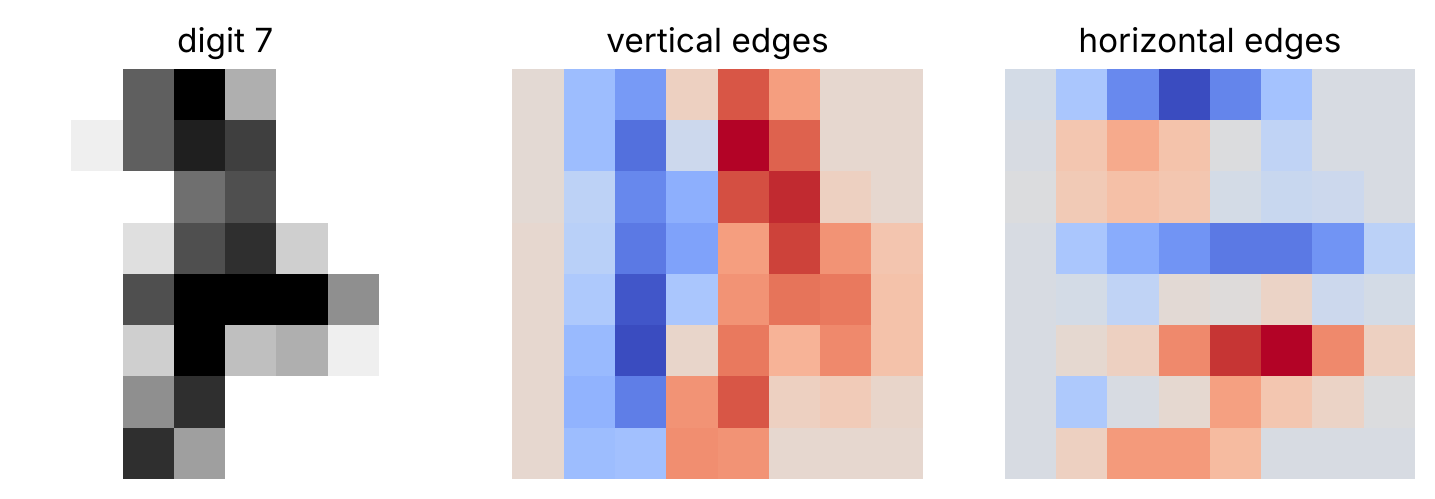

In [4]:
import torch.nn.functional as F
import matplotlib.pyplot as plt

vertical = torch.tensor([[1., 0., -1.], [1., 0., -1.], [1., 0., -1.]])
horizontal = vertical.T
filters = torch.stack([vertical, horizontal]).unsqueeze(1)    # shape (2 filters, 1 channel, 3, 3)

img = Xtr_img[:1]                                             # one image, shape (1, 1, 8, 8)
fmap = F.conv2d(img, filters, padding=1)                      # shape (1, 2, 8, 8)
print("input", tuple(img.shape), "-> feature maps", tuple(fmap.shape))

fig, axes = plt.subplots(1, 3, figsize=(9, 3))
axes[0].imshow(img[0, 0], cmap="gray_r"); axes[0].set_title(f"digit {y_train[0]}")
axes[1].imshow(fmap[0, 0], cmap="coolwarm"); axes[1].set_title("vertical edges")
axes[2].imshow(fmap[0, 1], cmap="coolwarm"); axes[2].set_title("horizontal edges")
for ax in axes: ax.axis("off")
plt.show()

## Part 2 · Max pooling

**Max pooling** with a 2×2 window keeps the largest value in each 2×2 block. Height and width halve: 8×8 → 4×4. The network becomes cheaper and cares less about tiny shifts.

In [5]:
pooled = F.max_pool2d(fmap, kernel_size=2)
print("before pooling", tuple(fmap.shape), "-> after", tuple(pooled.shape))
small = torch.tensor([[1., 3., 2., 0.], [4., 2., 1., 1.], [0., 1., 5., 6.], [2., 2., 7., 1.]])
print("4x4 example:\n", small)
print("after 2x2 max pool:\n", F.max_pool2d(small.reshape(1, 1, 4, 4), 2)[0, 0])

before pooling (1, 2, 8, 8) -> after (1, 2, 4, 4)
4x4 example:
 tensor([[1., 3., 2., 0.],
        [4., 2., 1., 1.],
        [0., 1., 5., 6.],
        [2., 2., 7., 1.]])
after 2x2 max pool:
 tensor([[4., 2.],
        [2., 7.]])


## Part 3 · Build the CNN

Architecture (shapes for one image):

| Layer | Output shape |
|---|---|
| input | 1×8×8 |
| `Conv2d(1, 16, 3, padding=1)` + ReLU | 16×8×8 |
| `MaxPool2d(2)` | 16×4×4 |
| `Conv2d(16, 32, 3, padding=1)` + ReLU | 32×4×4 |
| `MaxPool2d(2)` | 32×2×2 |
| flatten | 128 |
| `Dropout(0.25)` then `Linear(128, 10)` | 10 logits |

**Dropout** randomly switches off 25% of the values during training to reduce overfitting (more in notebook 04).

In [6]:
import torch.nn as nn

class DigitCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.dropout = nn.Dropout(0.25)
        self.fc = nn.Linear(32 * 2 * 2, 10)

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))   # (N, 16, 4, 4)
        x = self.pool(torch.relu(self.conv2(x)))   # (N, 32, 2, 2)
        x = x.flatten(start_dim=1)                 # (N, 128)
        return self.fc(self.dropout(x))            # (N, 10)

cnn = DigitCNN().to(device)
print(cnn)
print("parameters:", sum(p.numel() for p in cnn.parameters()))

DigitCNN(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.25, inplace=False)
  (fc): Linear(in_features=128, out_features=10, bias=True)
)
parameters: 6090


A habit that saves hours: push a fake batch through the layers and print the shape after each one. Shape mismatches are the most common CNN error.

In [7]:
x = torch.zeros(4, 1, 8, 8, device=device)
print("input      ", tuple(x.shape))
x = cnn.pool(torch.relu(cnn.conv1(x))); print("after block1", tuple(x.shape))
x = cnn.pool(torch.relu(cnn.conv2(x))); print("after block2", tuple(x.shape))
x = x.flatten(1);                       print("flattened   ", tuple(x.shape))
print("logits      ", tuple(cnn.fc(x).shape))

input       (4, 1, 8, 8)
after block1 (4, 16, 4, 4)
after block2 (4, 32, 2, 2)
flattened    (4, 128)
logits       (4, 10)


## Part 4 · A reusable training function

Same loop as notebook 02, wrapped in a function so we can train both an MLP and the CNN with identical settings for a fair comparison.

In [8]:
from torch.utils.data import TensorDataset, DataLoader

def train_model(model, X_tr, y_tr, X_va, y_va, epochs=30, lr=1e-3, batch_size=64):
    loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=batch_size, shuffle=True)
    loss_fn = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"train_loss": [], "val_loss": [], "val_acc": []}
    for epoch in range(epochs):
        model.train(); total = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            loss = loss_fn(model(xb), yb)
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(xb)
        hist["train_loss"].append(total / len(X_tr))
        model.eval()
        with torch.no_grad():
            out = model(X_va.to(device))
            hist["val_loss"].append(loss_fn(out, y_va.to(device)).item())
            hist["val_acc"].append((out.argmax(1) == y_va.to(device)).float().mean().item())
    return hist

def test_accuracy(model, X, y):
    model.eval()
    with torch.no_grad():
        return (model(X.to(device)).argmax(1) == y.to(device)).float().mean().item()

## Part 5 · Train the MLP and the CNN

We use the same number of epochs and learning rate for both. The MLP gets flat inputs; the CNN gets 1×8×8 images.

In [9]:
import time
torch.manual_seed(0)
mlp = nn.Sequential(nn.Linear(64, 128), nn.ReLU(), nn.Linear(128, 10)).to(device)
t0 = time.time(); mlp_hist = train_model(mlp, X_train_t, y_train_t, X_val_t, y_val_t); t_mlp = time.time() - t0

torch.manual_seed(0)
cnn = DigitCNN().to(device)
t0 = time.time(); cnn_hist = train_model(cnn, Xtr_img, y_train_t, Xval_img, y_val_t); t_cnn = time.time() - t0

print(f"MLP: test accuracy {test_accuracy(mlp, X_test_t, y_test_t):.3f}  "
      f"params {sum(p.numel() for p in mlp.parameters())}  time {t_mlp:.1f}s")
print(f"CNN: test accuracy {test_accuracy(cnn, Xte_img, y_test_t):.3f}  "
      f"params {sum(p.numel() for p in cnn.parameters())}  time {t_cnn:.1f}s")

MLP: test accuracy 0.956  params 9610  time 3.6s
CNN: test accuracy 0.967  params 6090  time 3.8s


Plot the validation curves side by side. On these tiny 8×8 images the difference is modest; on real photos (say 224×224 colour) CNNs win by a huge margin, because their filters re-use the same weights everywhere in the image.

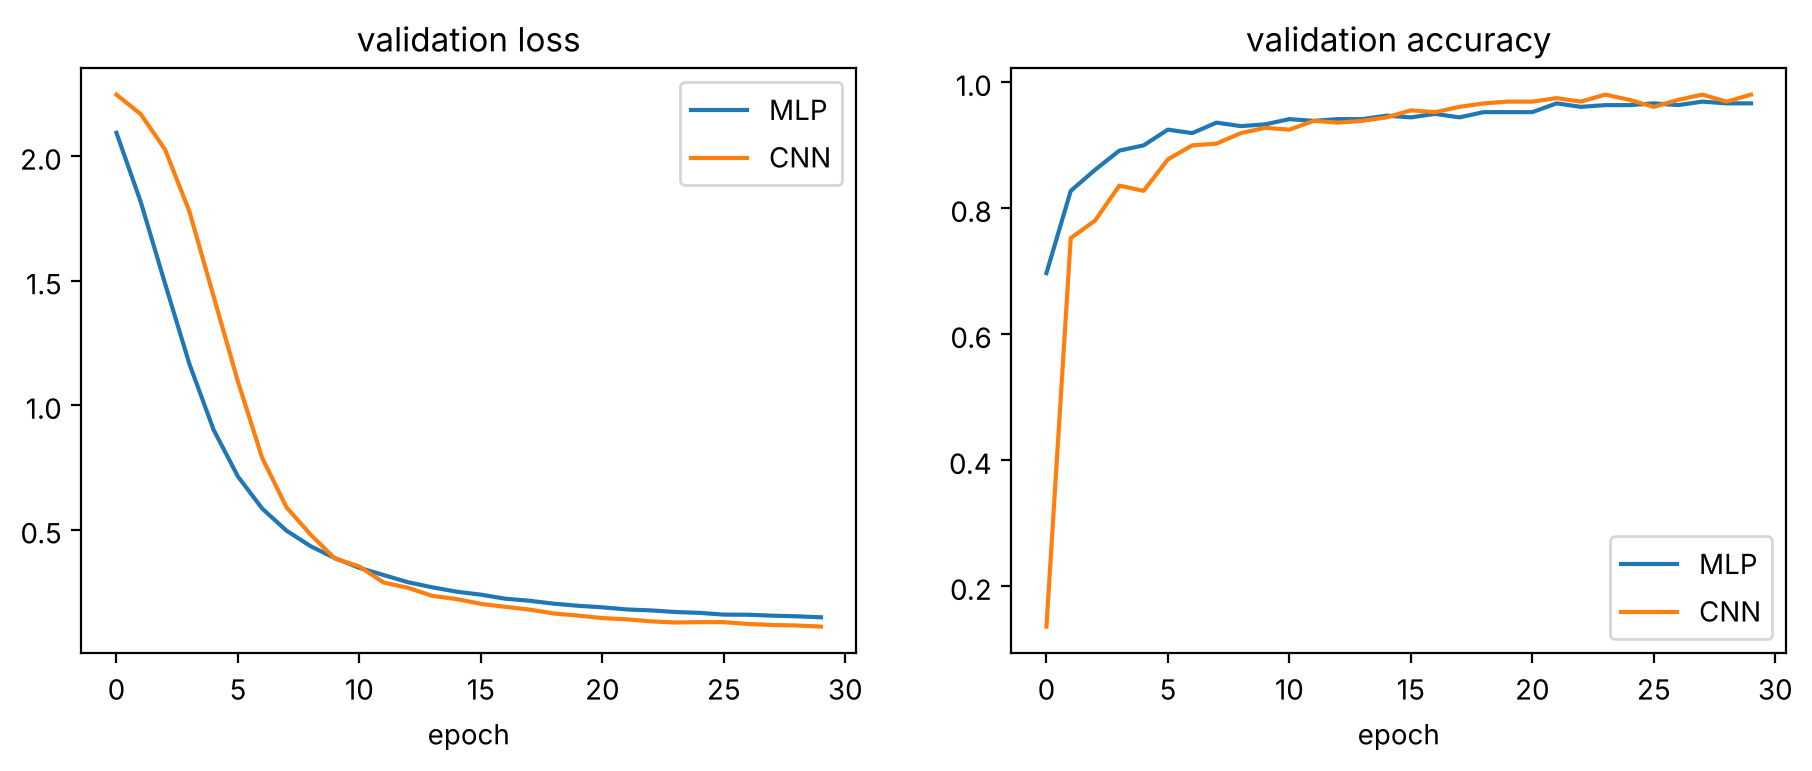

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(mlp_hist["val_loss"], label="MLP"); axes[0].plot(cnn_hist["val_loss"], label="CNN")
axes[0].set_title("validation loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(mlp_hist["val_acc"], label="MLP"); axes[1].plot(cnn_hist["val_acc"], label="CNN")
axes[1].set_title("validation accuracy"); axes[1].set_xlabel("epoch"); axes[1].legend()
plt.show()

## Part 6 · What did the CNN learn?

The first conv layer has 16 learned 3×3 filters. They start random; after training many look like small edge or corner detectors. Below: the filters, then the 16 feature maps they produce for one test digit.

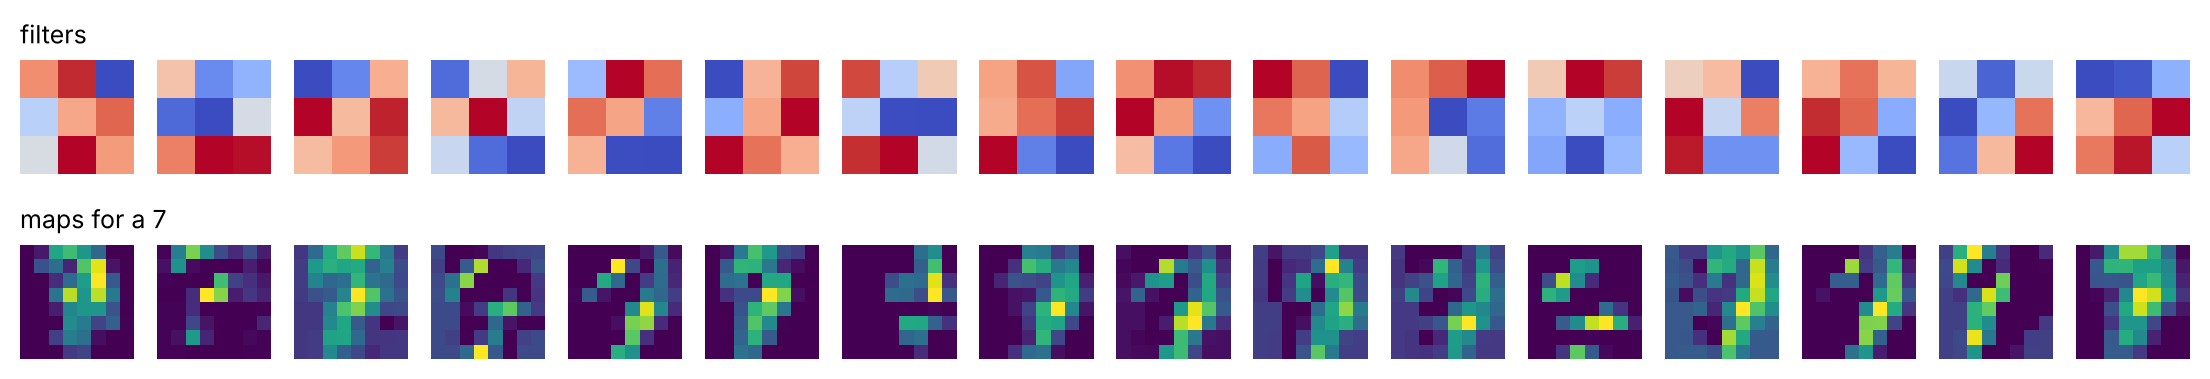

In [11]:
w = cnn.conv1.weight.detach().cpu()           # (16, 1, 3, 3)
fig, axes = plt.subplots(2, 16, figsize=(14, 2.2))
with torch.no_grad():
    maps = torch.relu(cnn.conv1(Xte_img[:1].to(device))).cpu()[0]   # (16, 8, 8)
for i in range(16):
    axes[0, i].imshow(w[i, 0], cmap="coolwarm"); axes[0, i].axis("off")
    axes[1, i].imshow(maps[i], cmap="viridis"); axes[1, i].axis("off")
axes[0, 0].set_title("filters", loc="left", fontsize=9)
axes[1, 0].set_title(f"maps for a {y_test[0]}", loc="left", fontsize=9)
plt.show()

## Recap

- Convolution slides a small filter over the image → feature map; filters are **learned**.
- Pooling shrinks feature maps (8×8 → 4×4).
- Shapes are (batch, channels, height, width); print shapes layer by layer when building a CNN.
- The training loop is unchanged — only the model changed.

**Try it:** add a third conv layer, or change 16/32 filters to 8/16. How do parameters and accuracy change?